#                                                Capstone Project    
## Neural Networks applied to the placement of digital cells

# Section 1   -  Problem statement and Theoretical background

In the section, we present the problem statement and objectives of this capstone project. Then, a short introduction to  therotical background  and literature review is provided. More details are given in the file data/capstone_project.pdf

In the following sections, we use the terms gates, instances and cell inetrchangeable

## 1.1.  Motivations

Adoption of ML/AI algorithm in ASIC design is becoming a hot topic. Hence, electronic design
automation (EDA) tools providers are increasingly integrating ML/AI algorithms in new generation of
their tools.

The main driven motivations for exploring the use of ML/AI algorithm in the domain of Application Specific Integrated Circuits ( ASIC) design are:

  - The run-time is considerably high even with powerful servers and cloud machines. This due to the high complexity and big size of advanced ASIC design. Therefore, the expectation is
high when it comes to the adoption of ML/AI to reduce run-time and complexity of advanced
designs.

  - The area of ML/AI is evolving at high speed. Hence, taking a lead in highly competitive
business.

## 1.2. Problem statement

The following figure depicts the flow of digital design. The step of interest is highlighted.
Use ML/AI algorithm to improve the auto-placement of standards (digital) cells. The complexity of
this step is related to 03 factors:

• Many User-defined constraints:
- Area constraints
- Functional constraints
- Timing-constraints
- power and signal integrity.
• Size of designs; millions of standards cells

## 1.3. Modeling the auto placement using Neural Networks 1.1.Literature Overview


In this section, we present different approaches used for the placement of digital cells, optimization objectives or metrics. Then a solution based on Neural Networks is introduced [2].
Placement of digital cells consists of three main steps:
•	global placement: Spreads out cells in the layout with a target cost minimized
•	legalization: Align cells to placement sites and remove overlaps
•	detailed placement: Performs incremental refinement to improve placement quality.


### 1.3.1 Global Placement Techniques
  -	Min-Cut Placement: Smaller sub-netlists and sub-regions
  -	Analytic Placement: Use an objective function. E.g. quadratic and force-directed placement
  -	Simulated Annealing
  -	Modern Placement Algorithms: eg.Stochastic, non-convex optimization placers


## 1.3.2 Optimization Objectives
  - Total Wirelength
  - Number of Cut Nets
  - Wire Congestion
  -	Signal Delay


Here, we limit the scope of this capstone project to Analytic Method with Total Wirelength as optimization function for 02 raisons:

  - The mathematical fonn of the cost function is more arlequate.
  - Nonlinear functions are best for optimization using the Gradient.


Different linear wirelength cost function are present in the file  

            data/capstone_project.pdf


## 1.4 Analytic Placement Method


Usually, global placement is the most time-consuming. Global placement aims at minimizing the wirelength cost subjecting to density constraints [2].

Where:

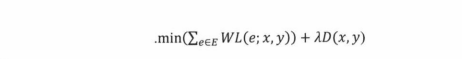

   -	WL() is the wirelength cost function that takes a net instance e and returns its wirelength.
  - D() the density penalty to spread cells out.
  - lambda is a regularization parameter.


## 1.5. Analogy of Placement nonlinear optimization to Neural Network Deep Learning


Similarities between Neural Networks learning process and nonlinear optimization placement problem.

  -	Wirelength cost function to the error of misprediction
  -	density cost to the regularization term.
  -	Neural networks are trained on data instances with a feature vector xi and label output Yi. It predicts a label ¢(xi ; w).
  -	Neural Network training aims to minimize the overall objective over weights w, where the objective consists of the prediction errors for all data instances, and a regularization term R(w).
  -	In the context of placement problem:
  -	Input dataset is all nets (paths between digital cells) with a feature vector e1 and a label 0. The feature vector ei is the list of digital cells connected to a net1 •

  More details are provided in the file   
  data/capstone_project.pdf


# Section 2  -  Data Preparation

## 2.1. From RTL to Gate Level  
  - Open source synthesis YOSYS
  - Chosen digital design with verilog behavioral model
  - YOSYS script to syntesis
  - Gate Level verilog model

### 2.1.1. YOSYS
 YOSYS is an open source framework  synthesis tool used widely in academia. The tool kernal is used in  major commercial tools.
 The ongoing  development, maintenance, and commercial support of the project are managed by YosysHQ GmbH,  https://www.yosyshq.com/


## 2.1.2. Chosen design

The chosen digital design is refered as the "fiedler cooley", which is 10 bits counter(up3down5) in verilog designed by Larry Fiedler(web source).
        
This design is a classic benchmark hardware design, widely used in the electronic design automation (EDA) industry to
test verilog synthesis tools, formal verification packages, and logic optimization engines like YosysHQ's Yosys(web source).
  - The verilog file is provided:         data/fiedler-cooley.v


## 2.1.3. YOSYS script
Steps required to sythesis the "fiedler cooley"  fiedler-cooley.v; converting the RTL(Register Transfer Level) verilog file into gate level netlist are grouped in this tcl(Tool Command Language; pronounced "tickle")  script file accessible in:    data/run_yosys.tcl

### 2.1.4. Gate Level model
After running the above run_yosys.tcl, the output is a gate level verilog file provided in  data/gate_level_netlist.v   
Also, YOSYS can provide provide graphical representation of the gate level netlist and JSON format.
  - gate level netlis is accessible in data/gate_level_netlist.v    
  - Graphical representation is accessible in data/graph.png
  - JASON formatted gate level netlist is in data/netlis_map.json

    


## 2.2. Data Preparation
  - Plot the gate level netlist
  - Graphical representation
  - Design Stat
  - Processing the netlist to provide Nets to Gates mapping

#### 2.2.1 Gate Level Netlist

We use the JASON format is it humain readable format. Here, a json parser is used to print the Gates Nets Mapping

In [ ]:
import json

# Load the Yosys JSON netlist
# Update the path to jason file if necessary

#with open("/home/abde/yosys/build/netlist_map.json", "r") as f:
with open("data/netlist_map.json", "r") as f:
    data = json.load(f)

# Top design module
module = data["modules"]["up3down5"]

print("--- GATE-NETS   MAPPING ---")
for gate_name, gate_info in module["cells"].items():
    gate_type = gate_info["type"]
    print(f"\nGate: {gate_name} ({gate_type})")

    # Extract the pins from the gate's ports info
    for pin_name, net_ids in gate_info["connections"].items():
        print(f"  Pin [{pin_name}] -> Connected to Net ID(s): {net_ids}")

--- GATE-NETS   MAPPING ---

Gate: _076_ (INV_X1)
  Pin [A] -> Connected to Net ID(s): [12]
  Pin [ZN] -> Connected to Net ID(s): [26]

Gate: _077_ (INV_X1)
  Pin [A] -> Connected to Net ID(s): [13]
  Pin [ZN] -> Connected to Net ID(s): [27]

Gate: _078_ (NOR2_X1)
  Pin [A1] -> Connected to Net ID(s): [28]
  Pin [A2] -> Connected to Net ID(s): [29]
  Pin [ZN] -> Connected to Net ID(s): [30]

Gate: _079_ (NOR3_X1)
  Pin [A1] -> Connected to Net ID(s): [28]
  Pin [A2] -> Connected to Net ID(s): [31]
  Pin [A3] -> Connected to Net ID(s): [29]
  Pin [ZN] -> Connected to Net ID(s): [32]

Gate: _080_ (OAI21_X1)
  Pin [A] -> Connected to Net ID(s): [33]
  Pin [B1] -> Connected to Net ID(s): [32]
  Pin [B2] -> Connected to Net ID(s): [19]
  Pin [ZN] -> Connected to Net ID(s): [34]

Gate: _081_ (AOI21_X1)
  Pin [A] -> Connected to Net ID(s): [35]
  Pin [B1] -> Connected to Net ID(s): [36]
  Pin [B2] -> Connected to Net ID(s): [34]
  Pin [ZN] -> Connected to Net ID(s): [37]

Gate: _082_ (OAI21_X

<br>  <br>


#### 2.2.3 Graphical Representation

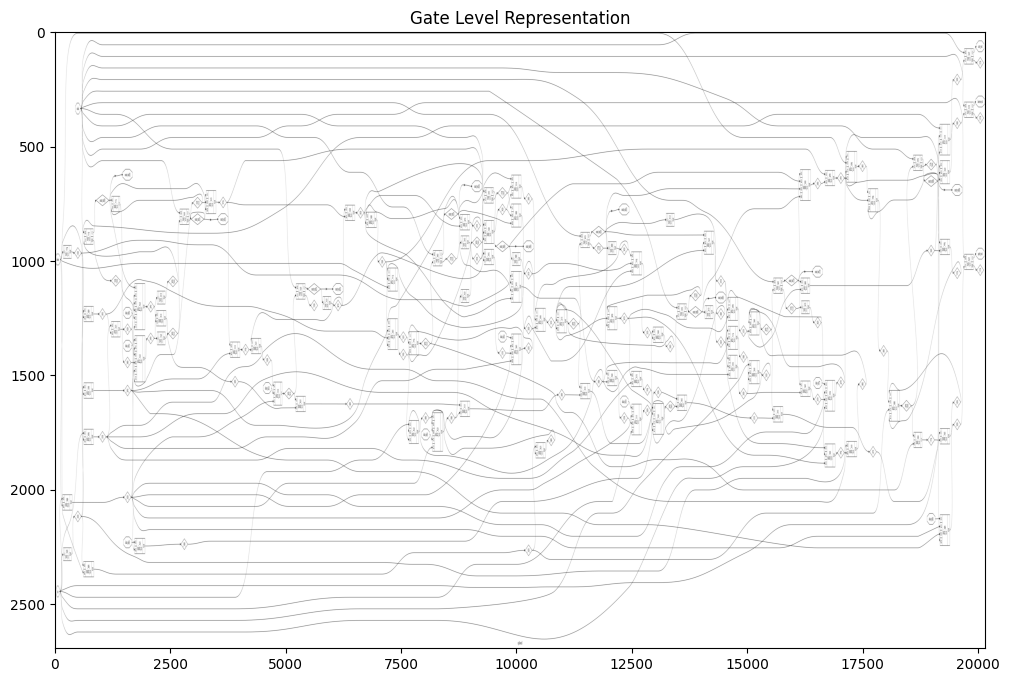

In [ ]:
import matplotlib.pyplot as plt


# Update the path to your local folder if necessary
#filename=("/home/abde/Downloads/data/graph.png")
filename=("data/graph.png")

# 1. Load the image
img = plt.imread(filename, format='png')

plt.figure(figsize=(12, 8))

# 2. Plot the image
plt.imshow(img, aspect='auto')
plt.title('Gate Level Representation' )

# 3. Display the window
plt.show()



<br>   <br>

#### 2.2.4 Statistics about the design

Using YOSYS stat command provides the following statistics.

Printing statistics.

=== up3down5 ===

        +----------Local Count, excluding submodules.
        |
      123 wires
      123 wire bits
      123 public wires
      123 public wire bits
       24 ports
       24 port bits
       90 cells
        2   AND3_X1
        2   AOI211_X1
        3   AOI21_X1
        1   AOI221_X1
        2   AOI222_X1
        5   AOI22_X1
       12   DFF_X1
       12   INV_X1
        1   MUX2_X1
        6   NAND2_X1
        3   NAND3_X1
        2   NAND4_X1
        9   NOR2_X1
        3   NOR3_X1
        2   OAI211_X1
        8   OAI21_X1
        2   OR2_X1
        1   OR3_X1
       12   XNOR2_X1
        2   XOR2_X1


#### 2.2.5 Processing the gate level netlist to extract the NETS-GATE MAPPING
As stated in the section 1, The placement algorithm requires the NETS-GATES mappings as input, whereas the gate level netlist is formated
as GATES-NETS mapping. In other words, the building blocs of gate level netlist is design gates and all nets connected to its ports.
    
The following steps are:
  - Parsing the gate level netlist and Extracting the GATES-NETS Mapping.
  - For each net, extract the list of gates which has a port connected to this net. Hence, building the NETS-GATES Mapping.
  - Data cleaning and conversion of  all entries to numerical values.
    

#### 2.2.5.1 Parsing the gate level net list and Extracting the NETS-GATES Mapping

In [ ]:
# Parsing the gate level netlist
!pip install pandas
import re, collections
import pandas as pd

df1_columns=['str_net', 'str_listGates']
df2_columns=['str_gate', 'str_gateTYPE']

# Working dataframes
dataset=pd.DataFrame(columns=df1_columns)
gatesInfo=pd.DataFrame(columns=df2_columns)

new_row=[]

nets = collections.defaultdict(list)

# Read the gate level netlist and Match gates and their Ports

# Update the path to the gate level netlist if necessary
#gate_matches = re.findall(r'(\S+)\s+(\S+)+\s*\((.*?)\);', open("/home/abde/yosys/build/gate_level_netlist5.v").read(), re.DOTALL)
gate_matches = re.findall(r'(\S+)\s+(\S+)+\s*\((.*?)\);', open("data/gate_level_netlist.v").read(), re.DOTALL)


#print(cell_matches)

for gate_type, gate_id,  ports in gate_matches:
    #print(cell_id)
    if gate_type.startswith('module'): continue
    # Extract net names inside .port(net)
    for net in re.findall(r'\.\w+\(([^)]+)\)', ports):
        nets[net.strip()].append(gate_id.strip())
        #nets[net.strip()].append(cell_id.strip())
        new_row=pd.DataFrame([{'str_gate':gate_id,'str_gateTYPE':gate_type}])
        gatesInfo=pd.concat([gatesInfo,new_row],ignore_index=True)

for net, gates in nets.items():
    #print(f'{net:<20} ' + ' '.join(gates))
    new_row=pd.DataFrame([{'str_net':net,'str_listGates':gates}])
    dataset=pd.concat([dataset,new_row],ignore_index=True)
    new_row=pd.DataFrame([{'str_gate':gate_id,'str_gateTYPE':gate_type}])
    gatesInfo=pd.concat([gatesInfo,new_row],ignore_index=True)



In [ ]:
# Rename all nets and gates with numrical and save all in dataframe
#dataset.head(15)
gatesInfo.head(20)
#dataset.info()
dataset.head()

,str_net,str_listGates
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13..."
1,_018_,"[_076_, _086_, _093_, _094_, _095_]"
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]"
3,_019_,"[_077_, _085_, _093_, _102_, _151_]"
4,_022_,"[_078_, _079_, _110_, _114_]"


<br>   <br>
####  2.2.5.2 Convert the feature str_net and str_listGates from string into numerical features

In [ ]:
dataset['num_net']=pd.factorize(dataset['str_net'])[0]


In [ ]:
dataset.head()

,str_net,str_listGates,num_net
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13...",0
1,_018_,"[_076_, _086_, _093_, _094_, _095_]",1
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]",2
3,_019_,"[_077_, _085_, _093_, _102_, _151_]",3
4,_022_,"[_078_, _079_, _110_, _114_]",4


#### 2.2.5.2 Convert of all entries in dataframe into numerical values

In [ ]:
# Strip catacter _ from gate ID, eg: _80_ becomes 80
def remove_(list_ids):
    return [id.strip("_") for id in list_ids]
dataset['num_listGates']=dataset['str_listGates'].apply(remove_)
dataset['num_listGates']=dataset['num_listGates'].apply(lambda x: pd.to_numeric(x).tolist())


In [ ]:
dataset.info()
dataset.head(50)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   str_net        114 non-null    object
 1   str_listGates  114 non-null    object
 2   num_net        114 non-null    int64 
 3   num_listGates  114 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.7+ KB


,str_net,str_listGates,num_net,num_listGates
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13...",0,"[76, 85, 89, 105, 111, 128, 138, 150]"
1,_018_,"[_076_, _086_, _093_, _094_, _095_]",1,"[76, 86, 93, 94, 95]"
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]",2,"[77, 86, 89, 94, 95, 127]"
3,_019_,"[_077_, _085_, _093_, _102_, _151_]",3,"[77, 85, 93, 102, 151]"
4,_022_,"[_078_, _079_, _110_, _114_]",4,"[78, 79, 110, 114]"
5,_027_,"[_078_, _079_, _113_, _153_]",5,"[78, 79, 113, 153]"
6,_028_,"[_078_, _090_, _102_, _142_, _145_]",6,"[78, 90, 102, 142, 145]"
7,_025_,"[_079_, _143_, _145_]",7,"[79, 143, 145]"
8,_029_,"[_079_, _080_, _125_]",8,"[79, 80, 125]"
9,\_075_[4],"[_080_, _125_, _161_]",9,"[80, 125, 161]"


<br>  <br>

#### 2.2.5.3 Prepare the dataset for the next step


In section 3. design_df is the working dataset with the NETS-GATES Mapping information.
    <br>  <br>

In [ ]:
design_df=dataset[['num_net','num_listGates']]
design_df.info()
design_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   num_net        114 non-null    int64 
 1   num_listGates  114 non-null    object
dtypes: int64(1), object(1)
memory usage: 1.9+ KB


,num_net,num_listGates
0,0,"[76, 85, 89, 105, 111, 128, 138, 150]"
1,1,"[76, 86, 93, 94, 95]"
2,2,"[77, 86, 89, 94, 95, 127]"
3,3,"[77, 85, 93, 102, 151]"
4,4,"[78, 79, 110, 114]"


# Section 3.  Using Neural Networks to solve the optimiztion problem of digital cells placement

  3.1. Neural Network Topology  
  3.2. Objective Function: WireLenght_loss and Density_loss  
  3.3. Optimizer Adam  
  3.4. Visualization  
  3.5. Metrics for evaluation and Next steps   


### 3.1. Neural Network Topology
  . Neural network is used as a solver for mathematical optimization problem.
Each gate is represented as a Neuron with its cartesian coordinates as its  tunning weights.  
  . 02 Neurons are connected if they belong to a net.  
  . Neural Network is  trained to minimize total loss of each net(WireLenght_loss +penality_factor*Density_loss).  
  . Ideally, the total loss is 0.  
  . Gates coordinates are the weights to optimize.  
  . The gradient descent is used through backpropagation to adjut the gates coordinates.  



## Global Initialization

In [ ]:
import tensorflow as tf
from tensorflow.keras import optimizers


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


#  .............................    Gloabl variables   .......................................
#  die_size - die_size/area (width and length) where digital cells are to be placed
#  nbr_gates - Number of gates in the design
#  l_gates list of gates
#  nbr - Number of nets in the design
#  l_nets - list of nets
#  gates_placement - Gates placement/list of cartersienne coordinates of all gates, as start piont all gates are placed randomly inside the macro/die

# Define the die size, grid size and gate heigh and width assuming all gates have the same heigh and width for simplicity
die_size=[100000,100000]
grid_size=5
gates_height=5
gates_width=5
# Get the nbr of gates/nets  and list gates/nets in the design
nbr_gates=gatesInfo.shape[0]
nbr_nets=design_df.shape[0]
l_gates=nbr_gates
l_nets=nbr_nets



## Initial Macro Floor Planning
Random placement of all gates.

In [ ]:
# Initial gates placement /macro initial floor planning
# Placing all gates randomly
# Future improvement FP according to pins placement, critical nets and clks
# At this stage, we need to convert the data regarding nets and gates into tensorflow variable objects

# Create a generator from a seed
g = tf.random.Generator.from_seed(42)

# Generate a tensor of random of cartesian coordinates x and y for each gates
#random_tensor = g.normal(shape=[nbr_gates, 2])
init_gates_positions=tf.Variable(tf.random.uniform(shape=[nbr_gates,2], minval=0, maxval=die_size[1], dtype=tf.float32))
#print(init_gates_positions)



## WireLength Loss function
  . Use Half Perimeter Wire Length(HPWL) method to estimate the WireLenght loss function for each net  
  . Log-Sum-Exp smooth function approximation  for max/min calculation(derivatives)  

In [ ]:
# Define WireLenght and Density function
def WireLenght_loss(gates_positions):
  # Increased alpha to prevent numerical overflow (e^(x/alpha)) when coordinates range up to 200
  alpha = 20.0
  wl_loss = 0.0

  # We iterate over all nets in the design
  for net in range(l_nets):
    # Retrieve x and y coordinates of all gates associated with the current net
    gates_coords = tf.gather(gates_positions, design_df.iloc[net, 1])
    x = gates_coords[:, 0]
    y = gates_coords[:, 1]

    # Log-Sum-Exp smooth function for max/min calculation
    x_max = alpha * tf.math.reduce_logsumexp(x / alpha)
    x_min = -alpha * tf.math.reduce_logsumexp(-x / alpha)
    y_max = alpha * tf.math.reduce_logsumexp(y / alpha)
    y_min = -alpha * tf.math.reduce_logsumexp(-y / alpha)

    wl_loss += (x_max - x_min) + (y_max - y_min)

  return wl_loss

In [ ]:
# loss=WireLenght_loss(init_gates_positions)
# print(loss)


## 3.2. Density Loss function
  . Placement grid is the smalled die zone that can holds the smallest gate(width).  
  . In modern designs, die area is split into unifrom grids.   
  . Since the grids are small, we define bins as basis unit for density_loss.

In [ ]:
def Density_loss(gates_positions):

    # Placement grid is the smalled die zone that can holds the smallest gate(width)
    # In modern designs, die area is split into unifrom grids
    # Since the grids are small, we define bins as basis unit for density_loss
    bin_w = tf.constant(die_size[0] / grid_size, dtype=tf.float32)
    bin_h = tf.constant(die_size[1] / grid_size, dtype=tf.float32)

    # For simplicity and differentiability, we can calculate the density grid using standard operations.
    density_grid = []

    # Calculate cell lower-left bounds based on center weights
    x_left = gates_positions[:, 0] - gates_width / 2
    y_bottom = gates_positions[:, 1] - gates_height / 2

    # Differentiable overlapping distribution to bins
    for i in range(grid_size):
        row_bins = []
        for j in range(grid_size):
            bin_x_start = tf.constant(i * (die_size[0] / grid_size), dtype=tf.float32)
            bin_x_end = bin_x_start + bin_w
            bin_y_start = tf.constant(j * (die_size[1] / grid_size), dtype=tf.float32)
            bin_y_end = bin_y_start + bin_h

            # Correct element-wise minimum and maximum using tf.minimum and tf.maximum
            overlap_x = tf.clip_by_value(
                tf.minimum(x_left + gates_width, bin_x_end) - tf.maximum(x_left, bin_x_start),
                clip_value_min=0.0,
                clip_value_max=float('inf')
            )
            overlap_y = tf.clip_by_value(
                tf.minimum(y_bottom + gates_height, bin_y_end) - tf.maximum(y_bottom, bin_y_start),
                clip_value_min=0.0,
                clip_value_max=float('inf')
            )

            bin_density = tf.reduce_sum(overlap_x * overlap_y)
            row_bins.append(bin_density)
        density_grid.append(tf.stack(row_bins))

    density_grid = tf.stack(density_grid)

    # Penalty calculation: Mean squared error above target balanced capacity
    target_capacity = tf.cast(tf.reduce_sum(gates_width * gates_height) / (grid_size * grid_size), tf.float32)
    area_overlap = tf.clip_by_value(density_grid - target_capacity, clip_value_min=0.0, clip_value_max=float('inf'))
    return tf.reduce_sum(area_overlap ** 2)

In [ ]:
type(init_gates_positions)

tensorflow.python.ops.resource_variable_ops.ResourceVariable

## 3.3. Using TensorFlow Optimizer  Adam that uses gradient descent derivative method

In [ ]:
# starting optimizer weights
gates_positions = tf.Variable(tf.cast(init_gates_positions, tf.float32), name='gates_positions')

# Instantiate the Adam optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.1)
density_weight = tf.constant(0.05, dtype=tf.float32)

# Optimization Loop
num_steps = 100
print("Starting placement optimization loop...")
for step in range(1, num_steps + 1):
    with tf.GradientTape() as tape:
        # Compute Custom Physical-Loss Metrics
        wl_loss = WireLenght_loss(gates_positions)
        density_loss = Density_loss(gates_positions)
        loss = wl_loss + (density_weight * density_loss)

    # Calculate the gradients
    gradients = tape.gradient(loss, [gates_positions])

    # Apply the gradients
    optimizer.apply_gradients(zip(gradients, [gates_positions]))

    # Print progress every 10 steps/Epoches
    if step % 10 == 0 or step == num_steps:
        print(f"Step {step:<2} | Loss: {loss.numpy():.4f} | WL: {wl_loss.numpy():.4f} | Density: {density_loss.numpy():.4f}")

Starting placement optimization loop...
Step 10 | Loss: 9798230.0000 | WL: 9543449.0000 | Density: 5095625.0000
Step 20 | Loss: 9797911.0000 | WL: 9543130.0000 | Density: 5095625.0000
Step 30 | Loss: 9797592.0000 | WL: 9542811.0000 | Density: 5095625.0000
Step 40 | Loss: 9797273.0000 | WL: 9542492.0000 | Density: 5095625.0000
Step 50 | Loss: 9796956.0000 | WL: 9542175.0000 | Density: 5095625.0000
Step 60 | Loss: 9796638.0000 | WL: 9541857.0000 | Density: 5095625.0000
Step 70 | Loss: 9796318.0000 | WL: 9541537.0000 | Density: 5095625.0000
Step 80 | Loss: 9796001.0000 | WL: 9541220.0000 | Density: 5095625.0000
Step 90 | Loss: 9795680.0000 | WL: 9540899.0000 | Density: 5095625.0000
Step 100 | Loss: 9795362.0000 | WL: 9540581.0000 | Density: 5095625.0000


## 3.4. Visualization
Following plot shows the placement of gates in the area of the die.   
This code was correcetd by AI tool Gemini

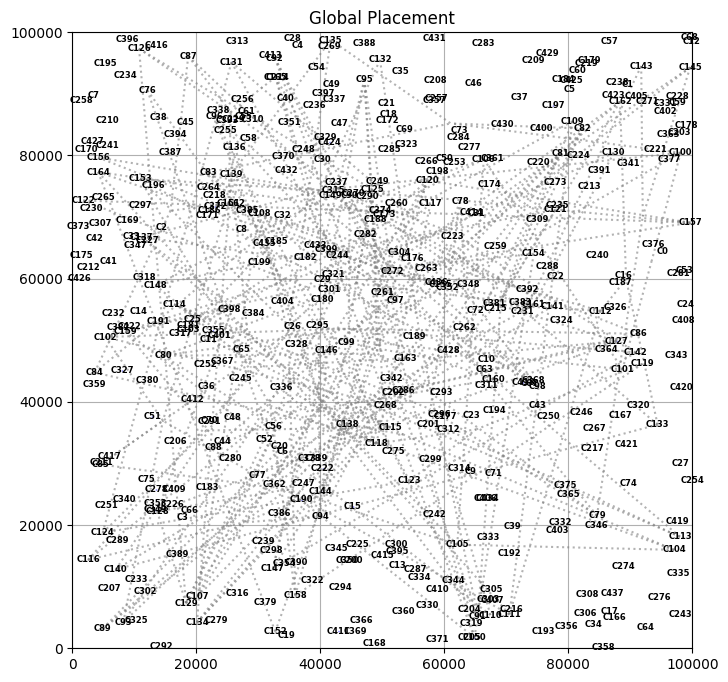

In [ ]:
final_positions = gates_positions.numpy()

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(0, die_size[0])
ax.set_ylim(0, die_size[1])
ax.set_title("Global Placement")

# Draw nets/wires first by iterating over integer indices of design_df
for net in range(nbr_nets):
    # Retrieve list of gates associated with this net

    gates_coords = tf.gather(gates_positions, design_df.iloc[net, 1]).numpy()


    center_of_net = np.mean(gates_coords, axis=0)
    for coord in gates_coords:
        ax.plot([coord[0], center_of_net[0]], [coord[1], center_of_net[1]], color='gray', linestyle=':', alpha=0.6)

# Draw Cells
for idx, (pos, w, h) in enumerate(zip(final_positions, [gates_width]*nbr_gates, [gates_height]*nbr_gates)):
    lower_left_x = pos[0] - w/2
    lower_left_y = pos[1] - h/2
    rect = plt.Rectangle((lower_left_x, lower_left_y), w, h, edgecolor='blue', facecolor='skyblue', alpha=0.7)
    ax.add_patch(rect)
    ax.text(pos[0], pos[1], f"C{idx}", ha='center', va='center', fontsize=6, weight='bold')

plt.grid(True)
plt.show()

In [ ]:
# gates_coords = tf.gather(gates_positions, design_df.iloc[20, 1]).numpy()
# gates_coords
# nbr_nets

## 3.5. Evaluation of placement algorithms

These are few metrics for evaluating placement algorithms:

  1. Utilization: ratio of occupied are to  the total available area.  
  2. Delays on critical nets: shorter nets the better for  delays.



### Next steps

  1. Fine-Tunning the following Hyper-parameters:  
     . Optimizer: Adam, AdamW, Nadam ...
     . Optimizer learning rate  
     . Density_weight  
     . Smooting parameter alpha for LSE smoothing function  
     . Number of Epoches or iterations

  2. Legalize placement  
   Since the placement area/die is split vertically into rows with uniform height, legalize placement will adjust the gates coordinates to match the die layout.

  3. Generate DEF file  
    Next step is routing. Commerical tools requires information about the gates placement stored in DEF (Design Exchange Format) file format.